In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import random
import urllib.request
import tarfile
import tensorflow as tf
from google.colab import files

In [3]:
os.makedirs('images', exist_ok=True)

uploaded_images = files.upload()

for filename in uploaded_images.keys():
    dest = os.path.join('images', filename)
    os.rename(filename, dest)
    print(f"Moved '{filename}' -> '{dest}'")

image_files = [f for f in os.listdir('images') if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
print(f"\nUploaded {len(image_files)} Image(s): {image_files}")

Saving alireza-in-workshop.jpg to alireza-in-workshop.jpg
Saving pedestrian.jpg to pedestrian.jpg
Moved 'alireza-in-workshop.jpg' -> 'images/alireza-in-workshop.jpg'
Moved 'pedestrian.jpg' -> 'images/pedestrian.jpg'

Uploaded 2 Image(s): ['alireza-in-workshop.jpg', 'pedestrian.jpg']


In [4]:
os.makedirs('model/tensorflow', exist_ok=True)

MODEL_URL = "http://download.tensorflow.org/models/object_detection/mask_rcnn_inception_v2_coco_2018_01_28.tar.gz"
TAR_PATH = "model/tensorflow/mask_rcnn_model.tar.gz"
PB_FILE = "model/tensorflow/mask_rcnn_inception_v2_coco_2018_01_28/frozen_inference_graph.pb"

print("Checking Model Files...")
if not os.path.exists(PB_FILE):
    print("Downloading Model...")
    urllib.request.urlretrieve(MODEL_URL, TAR_PATH)
    with tarfile.open(TAR_PATH, "r:gz") as tar:
      tar.extractall(path="model/tensorflow")
    os.remove(TAR_PATH)
    print("Model Downloaded")
else:
    print("Model Already Downloaded")

COCO_CLASSES = [
    "person", "bicycle", "car", "motorcycle", "airplane", "bus", "train", "truck", "boat",
    "traffic light", "fire hydrant", "stop sign", "parking meter", "bench", "bird", "cat",
    "dog", "horse", "sheep", "cow", "elephant", "bear", "zebra", "giraffe", "backpack",
    "umbrella", "handbag", "tie", "suitcase", "frisbee", "skis", "snowboard", "sports ball",
    "kite", "baseball bat", "baseball glove", "skateboard", "surfboard", "tennis racket",
    "bottle", "wine glass", "cup", "fork", "knife", "spoon", "bowl", "banana", "apple",
    "sandwich", "orange", "broccoli", "carrot", "hot dog", "pizza", "donut", "cake", "chair",
    "couch", "potted plant", "bed", "dining table", "toilet", "tv", "laptop", "mouse",
    "remote", "keyboard", "cell phone", "microwave", "oven", "toaster", "sink", "refrigerator",
    "book", "clock", "vase", "scissors", "teddy bear", "hair drier", "toothbrush"
]

LABELS_PATH = 'model/tensorflow/mscoco_labels.names'
with open(LABELS_PATH, 'w') as f:
    f.write('\n'.join(COCO_CLASSES))
print(f"Labels File Created: {LABELS_PATH}")

COLORS = {i: [random.randint(0, 255) for _ in range(3)] for i in range(len(COCO_CLASSES))}

Checking Model Files...


/tmp/ipykernel_1331/920234527.py:12: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path="model/tensorflow")


Model Downloaded
Labels File Created: model/tensorflow/mscoco_labels.names


In [5]:
print("Loading TensorFlow Graph...")

with tf.io.gfile.GFile(PB_FILE, 'rb') as f:
  graph_def = tf.compat.v1.GraphDef()
  graph_def.ParseFromString(f.read())

detection_graph = tf.Graph()
with detection_graph.as_default():
  tf.import_graph_def(graph_def, name='')

  image_tensor = detection_graph.get_tensor_by_name('image_tensor:0')
  detection_boxes = detection_graph.get_tensor_by_name('detection_boxes:0')
  detection_masks = detection_graph.get_tensor_by_name('detection_masks:0')
  detection_scores = detection_graph.get_tensor_by_name('detection_scores:0')
  detection_classes = detection_graph.get_tensor_by_name('detection_classes:0')
  num_detections = detection_graph.get_tensor_by_name('num_detections:0')

print("TensorFlow Graph Loaded")

Loading TensorFlow Graph...
TensorFlow Graph Loaded


Detected 16 Object(s) In images/pedestrian.jpg


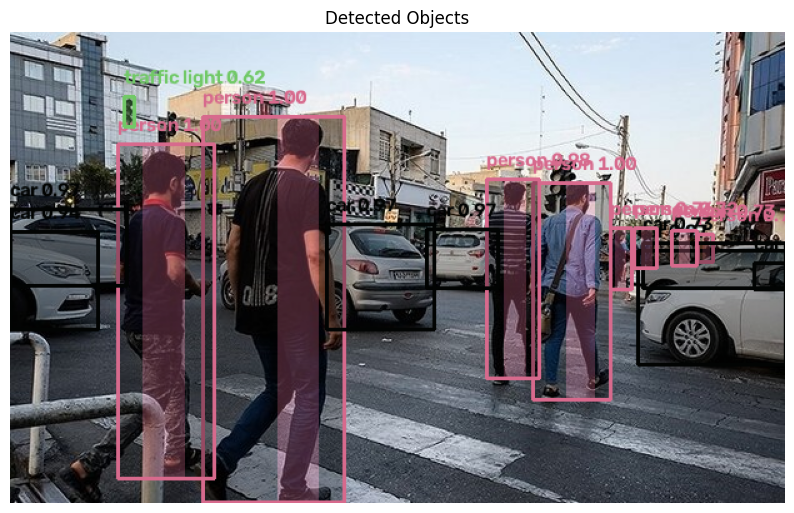

In [8]:
CONF_THRESHOLD = 0.5
MASK_THRESHOLD = 0.3

def detect_and_segment(img_path):
    img = cv2.imread(img_path)
    if img is None:
        print(f"Error: Unable To Read Image From {img_path}")
        return None

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_expanded = np.expand_dims(img_rgb, axis=0)

    with tf.compat.v1.Session(graph=detection_graph) as sess:
        boxes, masks, scores, classes_out, num = sess.run(
            [detection_boxes, detection_masks, detection_scores, detection_classes, num_detections],
            feed_dict={image_tensor: img_expanded}
        )

    h, w, _ = img.shape
    num_det = int(num[0])
    detected_count = 0

    for i in range(num_det):
        score = scores[0, i]
        if score > CONF_THRESHOLD:
            detected_count += 1
            class_id = int(classes_out[0, i]) - 1
            class_name = COCO_CLASSES[class_id] if 0 <= class_id < len(COCO_CLASSES) else "Unknown"
            color = COLORS.get(class_id, [255, 0, 0])

            ymin, xmin, ymax, xmax = boxes[0, i]
            left = int(xmin * w)
            right = int(xmax * w)
            top = int(ymin * h)
            bottom = int(ymax * h)

            left, right = max(0, left), min(w, right)
            top, bottom = max(0, top), min(h, bottom)

            mask = masks[0][i][int(classes_out[0, i])]
            mask_resized = cv2.resize(mask, (right - left, bottom - top))
            mask_binary = (mask_resized > MASK_THRESHOLD).astype(np.uint8)

            roi = img[top:bottom, left:right]
            colored_mask = np.zeros_like(roi, dtype=np.uint8)
            colored_mask[mask_binary == 1] = color
            img[top:bottom, left:right] = cv2.addWeighted(roi, 0.7, colored_mask, 0.3, 0)

            cv2.rectangle(img, (left, top), (right, bottom), color, 2)
            label = f"{class_name} {score:.2f}"
            cv2.putText(img, label, (left, max(15, top - 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

    print(f"Detected {detected_count} Object(s) In {img_path}")
    return img

target_image = 'images/pedestrian.jpg'
result_img = detect_and_segment(target_image)

if result_img is not None:
    plt.figure(figsize=(10, 10))
    plt.imshow(cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB))
    plt.title("Detected Objects")
    plt.axis('off')
    plt.show()


Processing 2 Image(s)...

--- Processing: alireza-in-workshop.jpg ---
Detected 4 Object(s) In images/alireza-in-workshop.jpg


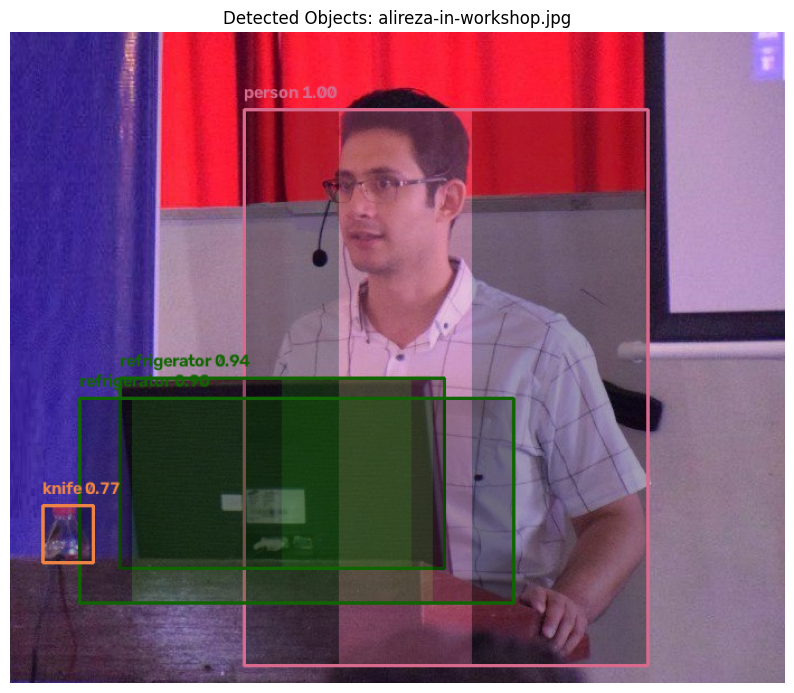

----------------------------------------
--- Processing: pedestrian.jpg ---
Detected 16 Object(s) In images/pedestrian.jpg


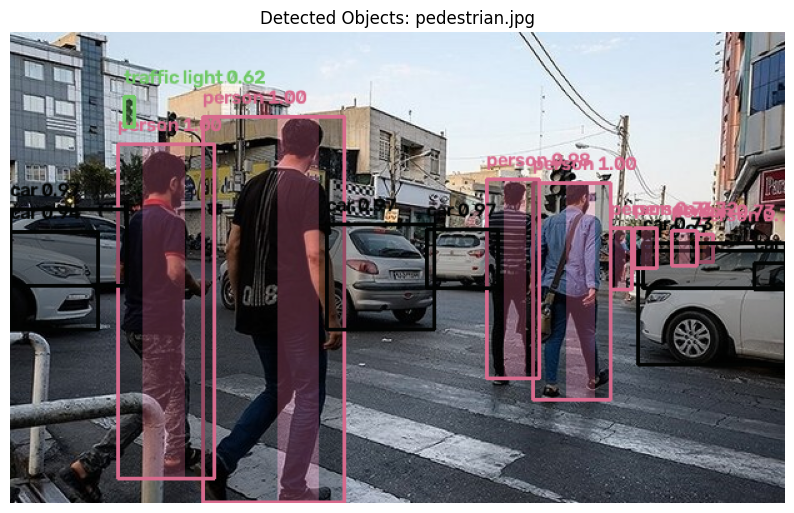

----------------------------------------


In [10]:
def detect_and_segment_safe(img_path):
    img = cv2.imread(img_path)
    if img is None:
        print(f"Error: Unable To Read Image From {img_path}")
        return None

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_expanded = np.expand_dims(img_rgb, axis=0)

    with tf.compat.v1.Session(graph=detection_graph) as sess:
        boxes, masks, scores, classes_out, num = sess.run(
            [detection_boxes, detection_masks, detection_scores, detection_classes, num_detections],
            feed_dict={image_tensor: img_expanded}
        )

    h, w, _ = img.shape
    num_det = int(num[0])
    detected_count = 0

    for i in range(num_det):
        score = scores[0, i]
        if score > CONF_THRESHOLD:
            detected_count += 1
            class_id = int(classes_out[0, i]) - 1
            class_name = COCO_CLASSES[class_id] if 0 <= class_id < len(COCO_CLASSES) else "Unknown"
            color = COLORS.get(class_id, [255, 0, 0])

            ymin, xmin, ymax, xmax = boxes[0, i]
            left = int(xmin * w)
            right = int(xmax * w)
            top = int(ymin * h)
            bottom = int(ymax * h)

            left, right = max(0, left), min(w, right)
            top, bottom = max(0, top), min(h, bottom)

            target_class_idx = int(classes_out[0, i])
            num_mask_classes = masks.shape[2]
            if target_class_idx >= num_mask_classes:
                target_class_idx = 0

            mask = masks[0][i][target_class_idx]
            mask_resized = cv2.resize(mask, (right - left, bottom - top))
            mask_binary = (mask_resized > MASK_THRESHOLD).astype(np.uint8)

            roi = img[top:bottom, left:right]
            colored_mask = np.zeros_like(roi, dtype=np.uint8)
            colored_mask[mask_binary == 1] = color
            img[top:bottom, left:right] = cv2.addWeighted(roi, 0.7, colored_mask, 0.3, 0)

            cv2.rectangle(img, (left, top), (right, bottom), color, 2)
            label = f"{class_name} {score:.2f}"
            cv2.putText(img, label, (left, max(15, top - 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

    print(f"Detected {detected_count} Object(s) In {img_path}")
    return img

if not image_files:
    print("No Images Found In The 'images' Folder.")
else:
    print(f"\nProcessing {len(image_files)} Image(s)...\n")

    for img_file in image_files:
        print(f"--- Processing: {img_file} ---")
        img_path = os.path.join('images', img_file)
        result_img = detect_and_segment_safe(img_path)

        if result_img is not None:
            plt.figure(figsize=(10, 10))
            plt.imshow(cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB))
            plt.title(f"Detected Objects: {img_file}")
            plt.axis('off')
            plt.show()
        print("-" * 40)